# 1. Data collection

Downloads the Sentinel-1 radar and the labels from Google Earth Engine for every region and year.

**No need to re-run the export to read this notebook.** The tables below are computed from the repo, and the logs are copies of the real run.
`RUN_EXPORT = False` skips every download. The dataset is about 20 GB, so it is linked from the README and not stored in git.

| Role | Source | Used for |
|---|---|---|
| Model input | Sentinel-1 GRD (`COPERNICUS/S1_GRD`), IW, VV and VH, one orbit direction per region | Training and inference |
| Training labels | Dynamic World (`GOOGLE/DYNAMICWORLD/V1`), monthly | Training, and the 2025 and 2026 tests |
| Independent checks | ESA WorldCover 2021, Esri LULC 2021 | Validation only, on the regions that have them |
| Sentinel-2 | Visual checks of the labels only | Never a model input |

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "lulc").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
RES = ROOT / "results"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "axes.grid": False})

# Where the exported data and full runs live. Set LULC_BASE to your own folder. Not needed to read or re-run this notebook.
BASE = os.environ.get("LULC_BASE", "/home/jovyan/vault/lulc" if Path("/home/jovyan/vault/lulc").is_dir() else str(ROOT / "data"))
OUT, RUNS, RUNS_MY = f"{BASE}/raw", f"{BASE}/runs", f"{BASE}/runs_multiyear"
PROJECT = os.environ.get("EE_PROJECT", "")     # your own Earth Engine project; no ID is stored in the repo
V12 = "V12_window3_balanced_stats"             # the shipped model

RUN_EXPORT = False     # True re-runs the slow steps below. They need Earth Engine and/or a GPU. Left False, nothing is downloaded or trained.
print("repo:", ROOT.name, "| data folder found:", Path(OUT).is_dir(), "|", "RUN_EXPORT =", RUN_EXPORT)

repo: sentinel1-lulc | data folder found: False | RUN_EXPORT = False


## Regions and years
Regions are split by place, never by tile, so no test region is seen in training. All settings are in `configs/regions.yaml`.

In [2]:
import yaml
from lulc.config import load_config, load_years
label_year, regions = load_config("configs/regions.yaml")
rdf = pd.DataFrame([{"region": r.key, "name": r.name, "split": r.split, "type": "city" if r.half_size_km > 6 else "rural",
                     "lat": r.lat, "lon": r.lon, "size_km": 2 * r.half_size_km, "climate": r.climate} for r in regions])
print("Years:", load_years("configs/regions.yaml"))
display(rdf.groupby(["split", "type"]).size().unstack(fill_value=0))

Years: {'train': [2021, 2022, 2023, 2024], 'val': [2024], 'test': [2025, 2026]}


type,city,rural
split,,
case_study,1,0
test,2,5
test_ood,3,29
train,10,11
val,2,4


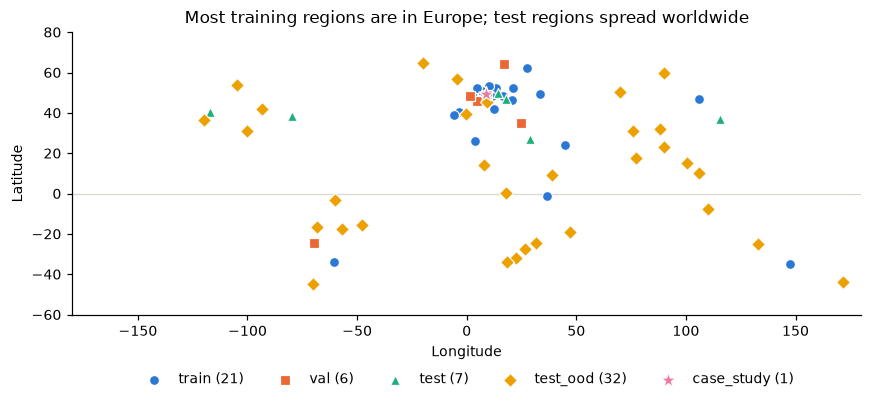

,region,name,split,type,lat,lon,size_km
0,heidelberg,Heidelberg,case_study,city,49.3988,8.6724,24.00
1,appalachians,Appalachians (trees),test,rural,38.6000,-79.8000,10.24
2,frankfurt,Frankfurt,test,city,50.1109,8.6821,24.00
3,great_basin,Great Basin (grass/shrub),test,rural,40.5000,-117.0000,10.24
4,lake_balaton,Lake Balaton (water),test,rural,46.8500,17.7500,10.24
...,...,...,...,...,...,...,...
62,beauce,Beauce (cropland),val,rural,48.2500,1.6000,10.24
63,crete,Crete (grass/shrub),val,rural,35.2000,24.9000,10.24
64,lyon,Lyon,val,city,45.7640,4.8357,24.00
65,stuttgart,Stuttgart,val,city,48.7758,9.1829,24.00


In [3]:
# Where the regions are. Shape and colour both mark the split; the full list follows in the table below.
styles = {"train": ("#2a78d6", "o"), "val": ("#eb6834", "s"), "test": ("#1baf7a", "^"), "test_ood": ("#eda100", "D"), "case_study": ("#e87ba4", "*")}
fig, ax = plt.subplots(figsize=(8, 3.8))
for split, (colour, marker) in styles.items():
    d = rdf[rdf.split == split]
    ax.scatter(d.lon, d.lat, s=42 if marker != "*" else 110, c=colour, marker=marker, edgecolors="#fcfcfb", linewidths=0.8, label=f"{split} ({len(d)})")
ax.set(xlabel="Longitude", ylabel="Latitude", xlim=(-180, 180), ylim=(-60, 80), title="Most training regions are in Europe; test regions spread worldwide")
ax.axhline(0, color="#d8d7d0", lw=0.8, zorder=0)
ax.legend(frameon=False, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.16))
plt.tight_layout(); plt.show()
display(rdf.drop(columns="climate").sort_values(["split", "region"]).reset_index(drop=True))

## Login and region lists
Earth Engine needs your own free noncommercial project, set in the `EE_PROJECT` environment variable.

In [4]:
if RUN_EXPORT:

    import ee
    try:
        ee.Initialize(project=PROJECT)
    except Exception:
        ee.Authenticate(auth_mode="notebook"); ee.Initialize(project=PROJECT)

In [5]:
keys = lambda *splits: " ".join(rdf.region[rdf.split.isin(splits)])
TRAIN, VAL, TEST, CASE = keys("train"), keys("val"), keys("test", "test_ood"), keys("case_study")
print(len(TRAIN.split()), "train |", len(VAL.split()), "val |", len(TEST.split()), "test |", len(CASE.split()), "case study")

21 train | 6 val | 39 test | 1 case study


## Check coverage before exporting
Reads the Sentinel-1 scenes per month and the Dynamic World coverage per year. Sentinel-1B stopped in December 2021, so later years have fewer scenes per month.

In [6]:
if RUN_EXPORT:
    SAMPLE = TRAIN.split()[0] + ' ' + TEST.split()[0]
    %run scripts/ee_year_stats.py --project $PROJECT --years 2021 2022 2023 2024 2025 2026 --regions $SAMPLE

**Saved log from the original run on Data Lab: coverage per year.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
[1/72] munich 2021 done
[2/72] munich 2022 done
[3/72] munich 2023 done
[4/72] munich 2024 done
[5/72] munich 2025 done
[6/72] munich 2026 done
[7/72] berlin 2021 done
[8/72] berlin 2022 done
[9/72] berlin 2023 done
[10/72] berlin 2024 done
[11/72] berlin 2025 done
[12/72] berlin 2026 done
[13/72] paris 2021 done
[14/72] paris 2022 done
[15/72] paris 2023 done
[16/72] paris 2024 done
[17/72] paris 2025 done
[18/72] paris 2026 done
[19/72] madrid 2021 done
[20/72] madrid 2022 done
... (165 lines left out; the full log is in notebooks/archive/multi_year.ipynb) ...
2022                  3.0             1          1.00             1.0                  1.0
2023                  2.5             2          1.00             1.0                  1.0
2024                  2.0             2          0.83             1.0                  0.0
2025                  3.0             2          1.00             1.0                  1.0
2026                  2.5             0          0.83             0.5                  0.0
Full table: reports/ee_year_stats.csv
```

## Orbit direction per region
Each region uses one orbit direction, so the viewing geometry does not change from month to month. This is the saved check.

In [7]:
print("\n".join((RES / "orbit_check.txt").read_text(encoding="utf8").splitlines()[:25]))

Regions per orbit direction: {'ASCENDING': 31, 'DESCENDING': 36}

Regions with MORE THAN ONE direction across all exported months: 0

Region-years with mixed directions inside one year: 0

Region-years with a median under 3 scenes per pixel or 3+ months without radar: 57
            region  year  direction  months  no_radar_months  scenes_median
       amazon_para  2025 DESCENDING      12                0            2.0
       amazon_para  2026 DESCENDING      10                0            2.5
      appalachians  2021  ASCENDING      12                0            2.0
      appalachians  2025  ASCENDING      12                0            2.5
      appalachians  2026  ASCENDING      10                0            2.0
     arabia_desert  2021  ASCENDING      12                0            2.0
     arabia_desert  2022  ASCENDING      12               12            0.0
     arabia_desert  2023  ASCENDING      12               12            0.0
     arabia_desert  2024  ASCENDING      12 

## Export
Resumable: re-run the cell if the session stops. Each region is one 2400 x 2400 px UTM grid at 10 m (the rural tiles are smaller), and Sentinel-1 and Dynamic World
come from one Earth Engine request per tile, so they share the grid. Output: `raw/<region>/<year>-<month>.npz`. `canada_boreal` has no 2021 files, so it is tested on 2025 and 2026 only.

In [8]:
# The same exports as the original runs, in one cell
if RUN_EXPORT:

    %run scripts/export_dataset.py --project $PROJECT --out $OUT --year 2021 --regions $TRAIN $VAL $TEST $CASE
    for y in (2022, 2023, 2024):
        %run scripts/export_dataset.py --project $PROJECT --out $OUT --year $y --regions $TRAIN
    %run scripts/export_dataset.py --project $PROJECT --out $OUT --year 2024 --regions $VAL
    %run scripts/export_dataset.py --project $PROJECT --out $OUT --year 2025 --regions $TEST
    %run scripts/export_dataset.py --project $PROJECT --out $OUT --year 2026 --months 1 2 3 4 5 6 7 8 9 10 --regions $TEST
    %run scripts/export_reference.py --project $PROJECT --out $OUT --regions $TEST     # WorldCover and Esri 2021: validation only

**Saved log from the original run on Data Lab: training years 2022 to 2024.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
=== training year 2022
munich: all requested months exist
berlin: all requested months exist
hamburg: all requested months exist
cologne: all requested months exist
paris: all requested months exist
amsterdam: all requested months exist
warsaw: all requested months exist
rome: all requested months exist
madrid: all requested months exist
... (487 lines left out; the full log is in notebooks/archive/multi_year.ipynb) ...
  2024-08 6s, left ~1 min | {"s1_valid": 0.0, "label_valid": 1.0, "both_valid": 0.0, "s1_scenes_median": 0.0, "label_conf_mean": 53.29}
  2024-09 9s, left ~1 min | {"s1_valid": 0.0, "label_valid": 1.0, "both_valid": 0.0, "s1_scenes_median": 0.0, "label_conf_mean": 51.334}
  2024-10 6s, left ~0 min | {"s1_valid": 0.0, "label_valid": 1.0, "both_valid": 0.0, "s1_scenes_median": 0.0, "label_conf_mean": 50.816}
  2024-11 7s, left ~0 min | {"s1_valid": 0.0, "label_valid": 1.0, "both_valid": 0.0, "s1_scenes_median": 0.0, "label_conf_mean": 50.082}
  2024-12 7s, left ~0 min | {"s1_valid": 0.0, "label_valid": 1.0, "both_valid": 0.0, "s1_scenes_median": 0.0, "label_conf_mean": 49.931}
Exported 251 region-months to /home/jovyan/vault/lulc/raw/
```

**Saved log from the original run on Data Lab: test year 2025.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
=== test year 2025
prague: all requested months exist
frankfurt: all requested months exist
milan: all requested months exist
valencia: all requested months exist
north_china_plain: all requested months exist
... (31 lines left out; the full log is in notebooks/archive/multi_year.ipynb) ...
pantanal_wetland: all requested months exist
siberia_taiga: all requested months exist
bangladesh_delta: all requested months exist
Exported 0 region-months to /home/jovyan/vault/lulc/raw/
```

**Saved log from the original run on Data Lab: test year 2026, January to October.** This text is a copy of the real output, so it stays visible when the notebook is re-run.

```text
=== test year 2026 (Jan-Oct)
prague: all requested months exist
frankfurt: all requested months exist
milan: all requested months exist
valencia: all requested months exist
north_china_plain: all requested months exist
... (31 lines left out; the full log is in notebooks/archive/multi_year.ipynb) ...
pantanal_wetland: all requested months exist
siberia_taiga: all requested months exist
bangladesh_delta: all requested months exist
Exported 0 region-months to /home/jovyan/vault/lulc/raw/
```

**Next:** `02_data_preprocessing.ipynb`.